In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import scipy as sp


from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (classification_report, 
                             confusion_matrix, root_mean_squared_error, 
                             mean_squared_error, mean_absolute_error, 
                             r2_score)
from sklearn.metrics.pairwise import cosine_similarity, euclidean_distances
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.decomposition import PCA, TruncatedSVD
from sklearn.manifold import TSNE


import heapq
import operator

import warnings
import os
os.environ["PYDEVD_DISABLE_FILE_VALIDATION"] = "1"


warnings.filterwarnings('ignore')

# Dataset Used in this Recommendation Project

* genome_scores.csv - a score mapping the strength between movies and tag-related properties. Read more here
* genome_tags.csv - user assigned tags for genome-related scores
* imdb_data.csv - Additional movie metadata scraped from IMDB using the links.csv file.
* links.csv - File providing a mapping between a MovieLens ID and associated IMDB and TMDB IDs.
* sample_submission.csv - Sample of the submission format for the hackathon.
* tags.csv - User assigned for the movies within the dataset.
* test.csv - The test split of the dataset. Contains user and movie IDs with no rating data.
* train.csv - The training split of the dataset. Contains user and movie IDs with associated rating data.

In [2]:
# genome_tags_path = r"C:\Users\Anthony\Pictures\alX-datascience\machine_learning\notebooks\week14\data\genome_tags.csv"
# genome_scores_path = r"C:\Users\Anthony\Pictures\alX-datascience\machine_learning\notebooks\week14\data\genome_scores.csv"
# imdb_path = r"C:\Users\Anthony\Pictures\alX-datascience\machine_learning\notebooks\week14\data\imdb_data.csv"
# links_path = r"C:\Users\Anthony\Pictures\alX-datascience\machine_learning\notebooks\week14\data\links.csv"
# movies_path = r"C:\Users\Anthony\Pictures\alX-datascience\machine_learning\notebooks\week14\data\movies.csv"
# sample_submission_path = r"C:\Users\Anthony\Pictures\alX-datascience\machine_learning\notebooks\week14\data\sample_submission.csv"
# tags_paths = r"C:\Users\Anthony\Pictures\alX-datascience\machine_learning\notebooks\week14\data\tags.csv"
# test_path = r"C:\Users\Anthony\Pictures\alX-datascience\machine_learning\notebooks\week14\data\test.csv"
# train_path = r"C:\Users\Anthony\Pictures\alX-datascience\machine_learning\notebooks\week14\data\train.csv"

In [3]:
genome_tags_path = r"/kaggle/input/competitions/movie-recommendation-hackathon-2026/genome_tags.csv"
genome_scores_path = r"/kaggle/input/competitions/movie-recommendation-hackathon-2026/genome_scores.csv"
imdb_path = r"/kaggle/input/competitions/movie-recommendation-hackathon-2026/imdb_data.csv"
links_path = r"/kaggle/input/competitions/movie-recommendation-hackathon-2026/links.csv"
movies_path = r"/kaggle/input/competitions/movie-recommendation-hackathon-2026/movies.csv"
sample_submission_path = r"/kaggle/input/competitions/movie-recommendation-hackathon-2026/sample_submission.csv"
tags_paths = r"/kaggle/input/competitions/movie-recommendation-hackathon-2026/tags.csv"
test_path = r"/kaggle/input/competitions/movie-recommendation-hackathon-2026/test.csv"
train_path = r"/kaggle/input/competitions/movie-recommendation-hackathon-2026/train.csv"

In [4]:
genome_scores = pd.read_csv(genome_scores_path)
genome_tags = pd.read_csv(genome_tags_path)
imdb = pd.read_csv(imdb_path)
links = pd.read_csv(links_path)
movies = pd.read_csv(movies_path)
sample_submission = pd.read_csv(sample_submission_path)
tags = pd.read_csv(tags_paths)
test = pd.read_csv(test_path)
train = pd.read_csv(train_path)

In [5]:
# genome_scores.head()

In [6]:
# genome_tags.head()

In [7]:
imdb.head()

,movieId,title_cast,director,runtime,budget,plot_keywords
0,1,Tom Hanks|Tim Allen|Don Rickles|Jim Varney|Wal...,John Lasseter,81.0,"$30,000,000",toy|rivalry|cowboy|cgi animation
1,2,Robin Williams|Jonathan Hyde|Kirsten Dunst|Bra...,Jonathan Hensleigh,104.0,"$65,000,000",board game|adventurer|fight|game
2,3,Walter Matthau|Jack Lemmon|Sophia Loren|Ann-Ma...,Mark Steven Johnson,101.0,"$25,000,000",boat|lake|neighbor|rivalry
3,4,Whitney Houston|Angela Bassett|Loretta Devine|...,Terry McMillan,124.0,"$16,000,000",black american|husband wife relationship|betra...
4,5,Steve Martin|Diane Keaton|Martin Short|Kimberl...,Albert Hackett,106.0,"$30,000,000",fatherhood|doberman|dog|mansion


In [8]:
links.head()

,movieId,imdbId,tmdbId
0,1,114709,862.0
1,2,113497,8844.0
2,3,113228,15602.0
3,4,114885,31357.0
4,5,113041,11862.0


In [9]:
movies.head()

,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance
4,5,Father of the Bride Part II (1995),Comedy


In [10]:
sample_submission.head()

,Id,rating
0,1_2011,1.0
1,1_4144,1.0
2,1_5767,1.0
3,1_6711,1.0
4,1_7318,1.0


In [11]:
tags.head()

,userId,movieId,tag,timestamp
0,3,260,classic,1439472355
1,3,260,sci-fi,1439472256
2,4,1732,dark comedy,1573943598
3,4,1732,great dialogue,1573943604
4,4,7569,so bad it's good,1573943455


In [12]:
test.head()

,userId,movieId
0,1,2011
1,1,4144
2,1,5767
3,1,6711
4,1,7318


In [13]:
train.head()

,userId,movieId,rating,timestamp
0,5163,57669,4.0,1518349992
1,106343,5,4.5,1206238739
2,146790,5459,5.0,1076215539
3,106362,32296,2.0,1423042565
4,9041,366,3.0,833375837


In [14]:
# # genome = pd.merge(genome_scores, genome_tags, on="tagId", how="outer")
# tags = tags.rename(columns={"tag": "user_tag", "timestamp": "tag_timestamp"})
# train = train.rename(columns={"timestamp": "rating_timestamp"})

In [15]:
def datafram_merg(imdb, links, movies, tags, test, train):
    """Aggregates user tags and blends movie metadata with train/test interactions

    into a clean, duplicate-free master DataFrame optimized for hybrid ML models.
    """
    # Standardize column names and drop noisy columns to save memory
    train = train.rename(columns={"timestamp": "rating_timestamp"})
    tags = tags.rename(columns={"tag": "user_tag"}).drop(
        columns=["timestamp"], errors="ignore"
    )

    # OPTIMIZATION: Aggregate duplicate tags per user-movie combo FIRST
    tags_clean = (
        tags.groupby(["userId", "movieId"])["user_tag"]
        .agg(lambda x: " ".join(x.dropna().astype(str).unique()))
        .reset_index()
    )

    # Combine your target datasets (train and test) together safely
    user_interactions = pd.merge(
        train, test, on=["userId", "movieId"], how="outer"
    )

    # Attach the pre-collapsed tags onto your interaction records
    user_data = pd.merge(
        user_interactions, tags_clean, on=["userId", "movieId"], how="left"
    )

    # Sequentially combine the unique movie-centric profile files
    movie_metadata = pd.merge(movies, links, on="movieId", how="outer")
    movie_metadata = pd.merge(movie_metadata, imdb, on="movieId", how="outer")

    # Final Left Join: Map movie profiles directly onto user interactions
    df = pd.merge(user_data, movie_metadata, on="movieId", how="left")

    return df


In [16]:
# data = datafram_merg(imdb, links, movies, tags, test, train)

In [17]:
# data.to_csv("movie_recommendation-1.csv", index=False)

In [18]:
# df = datafram_merg(imdb, links, movies, tags, test, train)
# df = pd.read_csv(r"C:\Users\Anthony\Pictures\alX-datascience\machine_learning\notebooks\week14\movie_recommendation-1.csv")
df = pd.read_csv(r"/kaggle/input/datasets/anthonyndegwa/xgboost-n-overall-merged-dataset/movie_recommendation-1.csv")

In [19]:
df.head(3)

,userId,movieId,rating,rating_timestamp,user_tag,title,genres,imdbId,tmdbId,title_cast,director,runtime,budget,plot_keywords
0,1,296,5.0,1.147880e+09,NaN,Pulp Fiction (1994),Comedy|Crime|Drama|Thriller,110912.0,680.0,Tim Roth|Amanda Plummer|Laura Lovelace|John Tr...,Quentin Tarantino,154.0,"$8,000,000",nonlinear timeline|overdose|drug overdose|bondage
1,1,665,5.0,1.147879e+09,NaN,Underground (1995),Comedy|Drama|War,114787.0,11902.0,Predrag 'Miki' Manojlovic|Lazar Ristovski|Mirj...,Dusan Kovacevic,170.0,"$14,000,000",magical realism|communism|zoo|black comedy
2,1,899,3.5,1.147869e+09,NaN,Singin' in the Rain (1952),Comedy|Musical|Romance,45152.0,872.0,NaN,NaN,NaN,NaN,NaN


In [20]:
df.shape

(15000057, 14)

In [21]:
# Save to excel format
# df.to_csv("movie_recommendation.xlsx", index=False)

In [22]:
df.columns

Index(['userId', 'movieId', 'rating', 'rating_timestamp', 'user_tag', 'title',
       'genres', 'imdbId', 'tmdbId', 'title_cast', 'director', 'runtime',
       'budget', 'plot_keywords'],
      dtype='object')

In [23]:
drop_col = ['imdbId', 'tmdbId', 'rating_timestamp']

df.drop(columns=drop_col, inplace=True)

In [24]:
df.isna().sum()

userId                  0
movieId                 0
rating            5000019
user_tag         14873703
title                   0
genres                  0
title_cast        4456767
director          4454227
runtime           4529537
budget            5277842
plot_keywords     4465065
dtype: int64

In [25]:
# remove $ in budget
# df['budget'] = df['budget'].str.replace('$', '')

In [26]:
text_cols = ["title", "genres", "title_cast", "director", "plot_keywords", "user_tag"]
for col in text_cols:
    df[col] = df[col].fillna("Unknown")

df["runtime"] = df["runtime"].fillna(df["runtime"].median())
df["budget"] = pd.to_numeric(
    df["budget"].astype("string").str.replace(r"[$,]", "", regex=True),
    errors="coerce"
)
df["budget"] = df["budget"].fillna(df["budget"].median())
df["userId"] = df["userId"].fillna(0)

In [27]:
# def fillnas(df):
#     text_cols = ["title", "genres", "title_cast", "director", "plot_keywords", "user_tag"]
#     for col in text_cols:
#         df[col] = df[col].fillna("Unknown")

#     df["runtime"] = df["runtime"].fillna(df["runtime"].median())
#     df["budget"] = df["budget"].fillna(df["budget"].median())
#     df["userId"] = df["userId"].fillna(0)

#     return df

# df = fillnas(df)

In [28]:
df.isna().sum()

userId                 0
movieId                0
rating           5000019
user_tag               0
title                  0
genres                 0
title_cast             0
director               0
runtime                0
budget                 0
plot_keywords          0
dtype: int64

In [29]:
df_train_clean = df[df["rating"].notnull()].copy()
df_test_clean = df[df["rating"].isnull()].copy()
df_test_clean = df_test_clean.drop(columns=["rating"])

In [30]:
df_train_clean.head()

,userId,movieId,rating,user_tag,title,genres,title_cast,director,runtime,budget,plot_keywords
0,1,296,5.0,Unknown,Pulp Fiction (1994),Comedy|Crime|Drama|Thriller,Tim Roth|Amanda Plummer|Laura Lovelace|John Tr...,Quentin Tarantino,154.0,8000000,nonlinear timeline|overdose|drug overdose|bondage
1,1,665,5.0,Unknown,Underground (1995),Comedy|Drama|War,Predrag 'Miki' Manojlovic|Lazar Ristovski|Mirj...,Dusan Kovacevic,170.0,14000000,magical realism|communism|zoo|black comedy
2,1,899,3.5,Unknown,Singin' in the Rain (1952),Comedy|Musical|Romance,Unknown,Unknown,113.0,40000000,Unknown
3,1,1175,3.5,Unknown,Delicatessen (1991),Comedy|Drama|Romance,Pascal Benezech|Dominique Pinon|Marie-Laure Do...,Jean-Pierre Jeunet,99.0,40000000,black comedy|absurd comedy|surrealist|bed
4,1,1217,3.5,Unknown,Ran (1985),Drama|War,Unknown,Unknown,113.0,40000000,Unknown


In [31]:
df_train_clean.shape

(10000038, 11)

In [32]:
df_train_clean.isna().sum()

userId           0
movieId          0
rating           0
user_tag         0
title            0
genres           0
title_cast       0
director         0
runtime          0
budget           0
plot_keywords    0
dtype: int64

In [33]:
df_train_clean.describe().T

,count,mean,std,min,25%,50%,75%,max
userId,10000038.0,81199.088145,46793.586156,1.0,40510.0,80914.0,121579.0,162541.0
movieId,10000038.0,21389.111613,39195.781053,1.0,1197.0,2947.0,8630.0,209171.0
rating,10000038.0,3.533395,1.061124,0.5,3.0,3.5,4.0,5.0
runtime,10000038.0,115.161315,20.178816,1.0,105.0,113.0,121.0,877.0
budget,10000038.0,48980462.45035,39410544.480362,0.0,30000000.0,40000000.0,52000000.0,300000000.0


In [34]:
# duplicate records

# Check for completely identical rows across the entire dataset
total_row_duplicates = df_train_clean.duplicated().sum()
print(f"Total completely duplicate rows in dataset: {total_row_duplicates} \n")

print("="*70)

# Check for duplicate user-movie interactions
# A single user should ideally only rate a specific movie once.
interaction_duplicates = df_train_clean.duplicated(subset=["userId", "movieId"]).sum()
print(f"Number of duplicate User-Movie interactions: {interaction_duplicates}\n")

print("="*70)

# duplicates per column, explicitly labeled as 'repeated values'
print("\n" + "=" * 50)
print("Analysis of Repeated Values Per Column:")
print("=" * 50)
for col in df_train_clean.columns:
    repeated_count = df_train_clean[col].duplicated().sum()
    print(f"Column '{col}' has {repeated_count} repeated values.")


Total completely duplicate rows in dataset: 0 

Number of duplicate User-Movie interactions: 0


Analysis of Repeated Values Per Column:
Column 'userId' has 9837497 repeated values.
Column 'movieId' has 9951825 repeated values.
Column 'rating' has 10000028 repeated values.
Column 'user_tag' has 9937401 repeated values.
Column 'title' has 9951887 repeated values.
Column 'genres' has 9998480 repeated values.
Column 'title_cast' has 9985506 repeated values.
Column 'director' has 9990042 repeated values.
Column 'runtime' has 9999781 repeated values.
Column 'budget' has 9999582 repeated values.
Column 'plot_keywords' has 9986246 repeated values.


In [35]:
df_train_clean.columns

Index(['userId', 'movieId', 'rating', 'user_tag', 'title', 'genres',
       'title_cast', 'director', 'runtime', 'budget', 'plot_keywords'],
      dtype='object')

In [36]:
n_unique = ["movieId", "title", "genres", "title_cast", "director", "userId"]

# A dictionary to provide a clear, readable explanation for each unique count
explanations = {
    "movieId": "Total unique movie IDs present in the training set",
    "title": "Total unique movie titles",
    "genres": "Distinct combinations of genres assigned to movies",
    "title_cast": "Unique cast list combinations available across entries(unique movie starring)",
    "director": "Total unique directors found in the dataset",
    "userId": "Total unique active users who provided data",
}

for item in n_unique:
    # Safely compute unique count from the cleaned training dataframe
    count = df_train_clean[item].nunique()

    # Dynamic print statements based on what column is being analyzed
    if item == "movieId" or item == "title":
        print(f"Number of unique movies ({item}): {count}")
    elif item == "userId":
        print(f"Number of unique users: {count}")
    else:
        print(f"Number of unique {item} categories: {count}")

    # Print the explanation for what this specific count means
    print(f"   ↳ Info: {explanations[item]}\n")

Number of unique movies (movieId): 48213
   ↳ Info: Total unique movie IDs present in the training set

Number of unique movies (title): 48151
   ↳ Info: Total unique movie titles

Number of unique genres categories: 1558
   ↳ Info: Distinct combinations of genres assigned to movies

Number of unique title_cast categories: 14532
   ↳ Info: Unique cast list combinations available across entries(unique movie starring)

Number of unique director categories: 9996
   ↳ Info: Total unique directors found in the dataset

Number of unique users: 162541
   ↳ Info: Total unique active users who provided data



In [37]:
df_train_clean.shape

(10000038, 11)

In [38]:
df_train_clean.info()

<class 'pandas.core.frame.DataFrame'>
Index: 10000038 entries, 0 to 15000056
Data columns (total 11 columns):
 #   Column         Dtype  
---  ------         -----  
 0   userId         int64  
 1   movieId        int64  
 2   rating         float64
 3   user_tag       object 
 4   title          object 
 5   genres         object 
 6   title_cast     object 
 7   director       object 
 8   runtime        float64
 9   budget         Int64  
 10  plot_keywords  object 
dtypes: Int64(1), float64(2), int64(2), object(6)
memory usage: 925.1+ MB


In [39]:
for col in df_train_clean.columns:
    print("=" * 70)
    counts = df_train_clean[col].value_counts()
    print(f"Number of unique values in {col}: {df_train_clean[col].nunique()}")
    print(counts)

Number of unique values in userId: 162541
userId
72315     12952
80974      3680
137293     3588
33844      3208
20055      3050
          ...  
127098        1
121071        1
105714        1
79087         1
55362         1
Name: count, Length: 162541, dtype: int64
Number of unique values in movieId: 48213
movieId
318       32831
356       32383
296       31697
593       29444
2571      29014
          ...  
200194        1
200190        1
200186        1
200182        1
200164        1
Name: count, Length: 48213, dtype: int64
Number of unique values in rating: 10
rating
4.0    2652977
3.0    1959759
5.0    1445230
3.5    1270642
4.5     880516
2.0     656821
2.5     505578
1.0     311213
1.5     159731
0.5     157571
Name: count, dtype: int64
Number of unique values in user_tag: 62637
user_tag
Unknown                                                                                                                                                                           9915532
comedy 

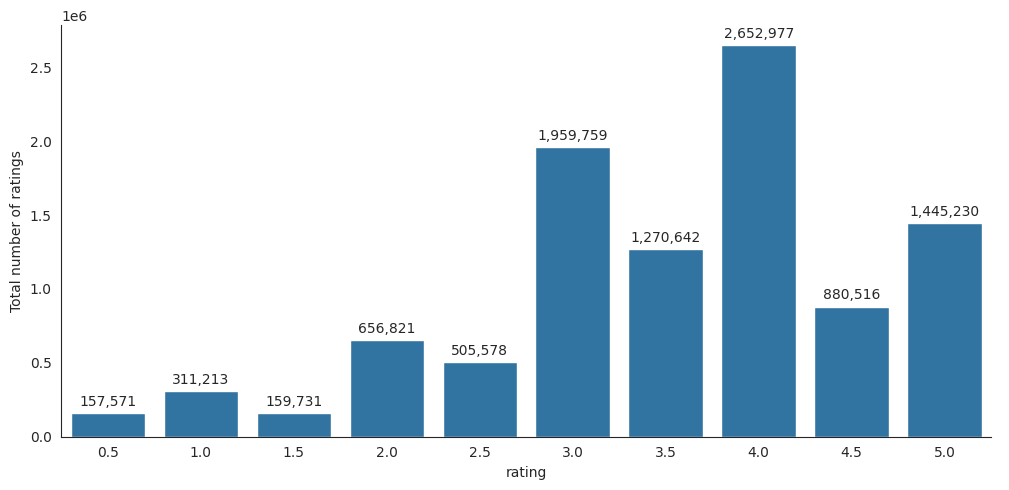

Average rating in dataset: 3.53


In [40]:
# Rating Distributions
with sns.axes_style("white"):
    g = sns.catplot(
        data=df_train_clean, x="rating", kind="count", aspect=2.0
    )
    g.set_ylabels("Total number of ratings")

    ax = g.ax
    for container in ax.containers:
        ax.bar_label(container, fmt="{:,.0f}", padding=3)

    g.figure.tight_layout()
    plt.show()

print(f'Average rating in dataset: {df_train_clean["rating"].mean():.2f}')

# Recommendation Method
## 1.  Content-based filtering 
In Content-based filtering, we seek to make recommendations based on **how similar an item's properties or features are to those of other items.**

In [41]:
df_train_clean.head(3)

,userId,movieId,rating,user_tag,title,genres,title_cast,director,runtime,budget,plot_keywords
0,1,296,5.0,Unknown,Pulp Fiction (1994),Comedy|Crime|Drama|Thriller,Tim Roth|Amanda Plummer|Laura Lovelace|John Tr...,Quentin Tarantino,154.0,8000000,nonlinear timeline|overdose|drug overdose|bondage
1,1,665,5.0,Unknown,Underground (1995),Comedy|Drama|War,Predrag 'Miki' Manojlovic|Lazar Ristovski|Mirj...,Dusan Kovacevic,170.0,14000000,magical realism|communism|zoo|black comedy
2,1,899,3.5,Unknown,Singin' in the Rain (1952),Comedy|Musical|Romance,Unknown,Unknown,113.0,40000000,Unknown


In [42]:
# Create a Unique Movie Metadata
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import linear_kernel

# Extracting unique movies to keep memory footprint minimal
movie_profiles = (
    df_train_clean[
        ["movieId", "title", "genres", "director", "runtime", "budget", "title_cast", "plot_keywords", "user_tag"]
    ]
    .drop_duplicates(subset=["movieId"])
    .copy()
)

# Cleanning text fields: replace spaces in names so "Tom Hanks" becomes "TomHanks"
# This prevents NLP models from confusing Tom Hanks with Tom Cruise.
for col in ["director", "title_cast"]:
    movie_profiles[col] = (
        movie_profiles[col].astype(str).str.replace(" ", "").str.replace("|", " ")
    )

# Create the Metadata Soup
movie_profiles["metadata_soup"] = (
    movie_profiles["genres"].str.replace("|", " ")
    + " "
    + movie_profiles["director"]
    + " "
    + movie_profiles["title_cast"]
    + " "
    + movie_profiles["plot_keywords"]
    + " "
    + movie_profiles["user_tag"]
)

# Clean up any residual 'Unknown' strings or double spaces
movie_profiles["metadata_soup"] = (
    movie_profiles["metadata_soup"]
    .str.lower()
    .str.replace("unknown", "")
    .str.strip()
)

In [43]:
movie_profiles.head()

,movieId,title,genres,director,runtime,budget,title_cast,plot_keywords,user_tag,metadata_soup
0,296,Pulp Fiction (1994),Comedy|Crime|Drama|Thriller,QuentinTarantino,154.0,8000000,TimRoth AmandaPlummer LauraLovelace JohnTravol...,nonlinear timeline|overdose|drug overdose|bondage,Unknown,comedy crime drama thriller quentintarantino t...
1,665,Underground (1995),Comedy|Drama|War,DusanKovacevic,170.0,14000000,Predrag'Miki'Manojlovic LazarRistovski Mirjana...,magical realism|communism|zoo|black comedy,Unknown,comedy drama war dusankovacevic predrag'miki'm...
2,899,Singin' in the Rain (1952),Comedy|Musical|Romance,Unknown,113.0,40000000,Unknown,Unknown,Unknown,comedy musical romance
3,1175,Delicatessen (1991),Comedy|Drama|Romance,Jean-PierreJeunet,99.0,40000000,PascalBenezech DominiquePinon Marie-LaureDougn...,black comedy|absurd comedy|surrealist|bed,Unknown,comedy drama romance jean-pierrejeunet pascalb...
4,1217,Ran (1985),Drama|War,Unknown,113.0,40000000,Unknown,Unknown,Unknown,drama war


In [44]:
df_train_clean.head(3)

,userId,movieId,rating,user_tag,title,genres,title_cast,director,runtime,budget,plot_keywords
0,1,296,5.0,Unknown,Pulp Fiction (1994),Comedy|Crime|Drama|Thriller,Tim Roth|Amanda Plummer|Laura Lovelace|John Tr...,Quentin Tarantino,154.0,8000000,nonlinear timeline|overdose|drug overdose|bondage
1,1,665,5.0,Unknown,Underground (1995),Comedy|Drama|War,Predrag 'Miki' Manojlovic|Lazar Ristovski|Mirj...,Dusan Kovacevic,170.0,14000000,magical realism|communism|zoo|black comedy
2,1,899,3.5,Unknown,Singin' in the Rain (1952),Comedy|Musical|Romance,Unknown,Unknown,113.0,40000000,Unknown


In [45]:
movie_profiles['metadata_soup'].head()

0    comedy crime drama thriller quentintarantino t...
1    comedy drama war dusankovacevic predrag'miki'm...
2                               comedy musical romance
3    comedy drama romance jean-pierrejeunet pascalb...
4                                            drama war
Name: metadata_soup, dtype: object

In [46]:
""" 
Transforming the text soup into a numerical matrix using TF-IDF (Term Frequency-Inverse Document Frequency)
"""
tfidf = TfidfVectorizer(stop_words="english", max_features=5000)

# Matrix construction
tfidf_matrix = tfidf.fit_transform(movie_profiles['metadata_soup'])

# Shape of the matrix
print(f"TF-IDF Matrix Shape {tfidf_matrix.shape}")

TF-IDF Matrix Shape (48213, 5000)


In [47]:
tfidf_matrix

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 222990 stored elements and shape (48213, 5000)>

In [48]:
# Mapping Matrix Indices for Fast Lookups

# Reset index of the profile table to line up perfectly with matrix row numbers
movie_profiles = movie_profiles.reset_index(drop=True)
movie_profiles.head(3)

,movieId,title,genres,director,runtime,budget,title_cast,plot_keywords,user_tag,metadata_soup
0,296,Pulp Fiction (1994),Comedy|Crime|Drama|Thriller,QuentinTarantino,154.0,8000000,TimRoth AmandaPlummer LauraLovelace JohnTravol...,nonlinear timeline|overdose|drug overdose|bondage,Unknown,comedy crime drama thriller quentintarantino t...
1,665,Underground (1995),Comedy|Drama|War,DusanKovacevic,170.0,14000000,Predrag'Miki'Manojlovic LazarRistovski Mirjana...,magical realism|communism|zoo|black comedy,Unknown,comedy drama war dusankovacevic predrag'miki'm...
2,899,Singin' in the Rain (1952),Comedy|Musical|Romance,Unknown,113.0,40000000,Unknown,Unknown,Unknown,comedy musical romance


In [49]:
# Create a mapping Series: Key = movieId, Value = Matrix Row Index
movie_indices = pd.Series(movie_profiles.index, index=movie_profiles["movieId"])

In [50]:
from sklearn.metrics.pairwise import linear_kernel


def get_recommendations_by_title(movie_title_input, top_n=10):
    """Finds and lists the top N movies most similar to the input title string

    based purely on their genres, directors, cast, keywords, and tags.
    """
    # Clean the input title string for matching
    clean_input = str(movie_title_input).strip().lower()

    # Search for the movie in the movie_profiles database using a partial match
    matched_movies = movie_profiles[
        movie_profiles["title"].str.lower().str.contains(clean_input, na=False)
    ]

    # Handle cases where the title isn't found or matches too many movies
    if matched_movies.empty:
        print(f"Movie '{movie_title_input}' not found in the database.")
        return None
    elif len(matched_movies) > 1:
        matched_movie = matched_movies.iloc[0]
        print(
            f"ℹMultiple matches found. Selected: '{matched_movie['title']}' (ID: {matched_movie['movieId']})"
        )
    else:
        matched_movie = matched_movies.iloc[0]

    # Extract the target movie's matrix row index
    target_movie_id = matched_movie["movieId"]
    idx = movie_indices[target_movie_id]

    # Computing cosine similarity scores between this movie and ALL other movies
    sim_scores = linear_kernel(tfidf_matrix[idx], tfidf_matrix).flatten()

    # Sorting the movies based on similarity scores in descending order
    sorted_indices = np.argsort(sim_scores)[::-1]

    # Excluding the input movie itself from its own recommendations
    sorted_indices = [i for i in sorted_indices if i != idx]

    # Extract the top_n movie profiles
    top_matches = movie_profiles.iloc[sorted_indices[:top_n]].copy()

    # Add the calculated similarity scores to the output dataframe for visibility
    top_matches["similarity_score"] = sim_scores[sorted_indices[:top_n]]

    print(
        f"\n Top {top_n} recommendations for fans of '{matched_movie['title']}':"
    )

    # Return a clean table showing the recommended titles and their genres
    return top_matches[["title", "genres", "similarity_score"]].reset_index(
        drop=True
    )

get_recommendations_by_title(movie_title_input="Toy Story", top_n=5)

ℹMultiple matches found. Selected: 'Toy Story (1995)' (ID: 1)

 Top 5 recommendations for fans of 'Toy Story (1995)':


,title,genres,similarity_score
0,Toy Story 2 (1999),Adventure|Animation|Children|Comedy|Fantasy,0.729438
1,Toy Story 3 (2010),Adventure|Animation|Children|Comedy|Fantasy|IMAX,0.527840
2,Toy Story Toons: Small Fry (2011),Adventure|Animation|Children|Comedy|Fantasy,0.467035
3,Toy Story That Time Forgot (2014),Animation|Children,0.437192
4,Toy Story Toons: Partysaurus Rex (2012),Animation|Children|Comedy,0.427153


In [51]:
get_recommendations_by_title("Terminator", top_n=5)

ℹMultiple matches found. Selected: 'Terminator 2: Judgment Day (1991)' (ID: 589)

 Top 5 recommendations for fans of 'Terminator 2: Judgment Day (1991)':


,title,genres,similarity_score
0,Primer (2004),Drama|Sci-Fi,0.385818
1,"Sticky Fingers of Time, The (1997)",Sci-Fi,0.344039
2,Predestination (2014),Action|Mystery|Sci-Fi|Thriller,0.321297
3,Frequently Asked Questions About Time Travel (...,Comedy|Sci-Fi,0.311050
4,Right America: Feeling Wronged - Some Voices f...,Documentary,0.309888


In [52]:
get_recommendations_by_title("The Matrix", top_n=5)

ℹMultiple matches found. Selected: 'Return to Source: The Philosophy of The Matrix (2004)' (ID: 132490)

 Top 5 recommendations for fans of 'Return to Source: The Philosophy of The Matrix (2004)':


,title,genres,similarity_score
0,Jag vill inte leva detta livet (2008),Documentary,1.0
1,Planet Earth II (2016),Documentary,1.0
2,Lynyrd Skynyrd - Freebird... The Movie (1996),Documentary,1.0
3,The Life and Times of Frida Kahlo (2005),Documentary,1.0
4,National Geographic: Incredible Human Machine ...,Documentary,1.0


## 2. Collaborative Filtering (User-Behavior & Similarity)

In content-based filtering, we looked at the similarity between the properties or attributes of items. In collaborative-based filtering, **we measure the similarity between users to make recommendations**.

In [53]:
# Create a Sparse User-Item Matrix
""" 
convert our flat df_train_clean into a matrix where rows are users, columns are movies, 
and cells contain ratings. To prevent memory crashes, 
we convert this into a compressed SciPy sparse matrix.
"""
from scipy.sparse import csr_matrix


# Create unique categorical mappings for fast lookups
df_train_clean['user_code'] = df_train_clean['userId'].astype('category').cat.codes
df_train_clean['movie_code'] = df_train_clean['movieId'].astype('category').cat.codes

# Saving these mappings so I can easily translate back and forth
user_map = dict(enumerate(df_train_clean['userId'].astype('category').cat.categories))
movie_map = dict(enumerate(df_train_clean['movieId'].astype('category').cat.categories))
inverse_movie_map = {v: k for k, v in movie_map.items()}

# compressed sparse row (CSR) Implementation
# Matrix shape: (Total Unique Users, Total Unique Movies)
sparse_matrix = csr_matrix((
    df_train_clean['rating'],
    (df_train_clean['user_code'], df_train_clean['movie_code'])
))

print(f"Sparse Matrix Shape: {sparse_matrix.shape}")


Sparse Matrix Shape: (162541, 48213)


In [54]:
# Compute Movie-to-Movie Cosine Similarities
""" 
Using the K-Nearest Neighbors (KNN) with brute force cosine metrics
This lets me find similar items on-demand or in highly compressed blocks.
"""
from sklearn.neighbors import NearestNeighbors

knn_model = NearestNeighbors(metric='cosine', algorithm='brute', n_neighbors=20, n_jobs=1)
knn_model.fit(sparse_matrix.T)

NearestNeighbors(algorithm='brute', metric='cosine', n_jobs=1, n_neighbors=20)

In [55]:
# Mapping Movie Titles to IDs for Input Lookups
# Creating a dictionary mapping: title -> movieId
title_to_id = pd.Series(movie_profiles['movieId'].values, index=movie_profiles['title'].str.lower().str.strip()).to_dict()
# Creating an inverse dictionary: movieId -> original Title string
id_to_title = pd.Series(movie_profiles['title'].values, index=movie_profiles['movieId']).to_dict()

In [56]:
# Item-Item Prediction Engine
def get_collaborative_recommendations(movie_title_input, top_n=10):
    """
    This function takes a Movie Title, finds its underlying code inside our 
    sparse matrix, runs the kNN model, and returns the top movies that share 
    identical user rating behavior
    """
    clean_input = str(movie_title_input).strip().lower()
    
    # Finding the movieId from the string input (fuzzy partial match helper)
    matched_id = None
    for title, mid in title_to_id.items():
        if clean_input in title:
            matched_id = mid
            break
            
    if matched_id is None or matched_id not in inverse_movie_map:
        print(f"Movie '{movie_title_input}' not found or has no rating history.")
        return None
        
    # Extract the internal matrix column code for this movie
    movie_col_idx = inverse_movie_map[matched_id]
    
    # Using kNN to find the closest neighbors ( ie fetching top_n + 1 because the closest is always itself)
    # distances are (1 - cosine_similarity), so 0 means perfectly identical rating behavior
    distances, indices = knn_model.kneighbors(
        sparse_matrix.T[movie_col_idx].reshape(1, -1), 
        n_neighbors=top_n + 1
    )
    
    # Format outputs into a readable dataframe
    raw_recs = []
    for i in range(1, len(indices.flatten())): # Skip index 0 (the input movie itself)
        neighbor_idx = indices.flatten()[i]
        neighbor_movie_id = movie_map[neighbor_idx]
        
        # Translate back to real title string
        title_string = id_to_title.get(neighbor_movie_id, "Unknown Title")
        similarity_score = 1 - distances.flatten()[i] # Convert distance to similarity profile
        
        raw_recs.append({
            "title": title_string,
            "collab_similarity_score": round(similarity_score, 4)
        })
        
    print(f"\n Collaborative Filtering: Users who liked '{id_to_title[matched_id]}' also enjoyed:")
    return pd.DataFrame(raw_recs)

In [57]:
get_collaborative_recommendations(movie_title_input="Toy Story", top_n=5)


 Collaborative Filtering: Users who liked 'Toy Story (1995)' also enjoyed:


,title,collab_similarity_score
0,Star Wars: Episode IV - A New Hope (1977),0.2271
1,Toy Story 2 (1999),0.2235
2,Back to the Future (1985),0.2182
3,Forrest Gump (1994),0.2181
4,Aladdin (1992),0.2175


In [58]:
get_collaborative_recommendations(movie_title_input="The Matrix", top_n=5)


 Collaborative Filtering: Users who liked 'Return to Source: The Philosophy of The Matrix (2004)' also enjoyed:


,title,collab_similarity_score
0,No Limit (1935),0.4454
1,"Juliette, or Key of Dreams (1951)",0.4454
2,Love and Fear (1988),0.4454
3,This Is Not a Love Song (2002),0.4454
4,Zubeidaa (2001),0.4454


In [59]:
get_collaborative_recommendations(movie_title_input="Terminator", top_n=5)


 Collaborative Filtering: Users who liked 'Terminator 2: Judgment Day (1991)' also enjoyed:


,title,collab_similarity_score
0,"Terminator, The (1984)",0.2779
1,Jurassic Park (1993),0.2741
2,Speed (1994),0.2520
3,"Fugitive, The (1993)",0.2497
4,Die Hard (1988),0.2436


# 3. Latent-Factor Models (Dimensionality Reduction)

* They are used to discover hidden patterns in how users interact with movies. 
* Instead of comparing users or movies directly, learn a smaller set of hidden characteristics that explain why users like particular movies.
* These hidden characteristics are called latent factors

In [60]:
from surprise import Dataset, Reader, SVD

In [61]:
# Building the Latent-Factor Data Pipeline

# Defining rating boundaries (MovieLens scale)
reader = Reader(rating_scale=(0.5, 5.0))

# Loading the dataset following this strict order: User, Item, Rating
data = Dataset.load_from_df(
    df_train_clean[["userId", "movieId", "rating"]], reader
)

# Building a complete training set structure
trainset = data.build_full_trainset()
print(f"Latent matrix space loaded: {trainset.n_users} users x {trainset.n_items} items.")


Latent matrix space loaded: 162541 users x 48213 items.


In [62]:
# Training the Latent-Factor Model [Singular Value Decomposition(SVD)]

# Initializing SVD with balanced hyperparameters
# n_factors=100 means the model uncovers 100 hidden dimensional features
svd_model = SVD(n_factors=100, lr_all=0.005, reg_all=0.02, random_state=42)

print("Factoring matrix patterns in the background...")
svd_model.fit(trainset)
print("SVD Latent-Factor model trained successfully!")


Factoring matrix patterns in the background...
SVD Latent-Factor model trained successfully!


In [63]:
# Title-Based Latent Predictor
def get_latent_recommendations(movie_title_input, top_n=10):
    """Finds items sharing the closest hidden characteristics using Latent-Factor Embeddings."""
    clean_input = str(movie_title_input).strip().lower()
    
    # Fuzzy matching to grab the true movieId
    matched_id = None
    for title, mid in title_to_id.items():
        if clean_input in title:
            matched_id = mid
            break
            
    if matched_id is None:
        print(f"Movie '{movie_title_input}' not found in profiles.")
        return None
        
    try:
        # Extract the internal raw integer code Surprise assigned to this movie
        inner_movie_id = trainset.to_inner_iid(matched_id)
    except ValueError:
        print(f" Movie '{id_to_title.get(matched_id, movie_title_input)}' has no user rating history to build factors.")
        return None

    # Extracting the hidden vector embeddings for ALL movies known by SVD
    # svd_model.qi is an array of shape (Total Movies, 50 Factors)
    all_movie_vectors = svd_model.qi
    target_vector = all_movie_vectors[inner_movie_id].reshape(1, -1)
    
    # Compute cosine similarity across all latent factor dimensions
    similarities = cosine_similarity(target_vector, all_movie_vectors).flatten()
    
    # Sort indices by highest matching scores descending
    sorted_indices = np.argsort(similarities)[::-1]
    
    raw_recs = []
    for idx in sorted_indices:
        # Convert inner index back to real world movieId
        raw_mid = trainset.to_raw_iid(idx)
        
        # Stop collecting when we hit our target top_n limit (and skip the source movie itself)
        if raw_mid == matched_id:
            continue
            
        title_string = id_to_title.get(raw_mid, "Unknown Title")
        raw_recs.append({
            "title": title_string,
            "latent_similarity_score": round(similarities[idx], 4)
        })
        
        if len(raw_recs) >= top_n:
            break
            
    print(f"\n Latent-Factor Model: Movies with similar hidden features to '{id_to_title[matched_id]}':")
    return pd.DataFrame(raw_recs)

In [64]:
get_latent_recommendations(movie_title_input="Toy Story", top_n=5)


 Latent-Factor Model: Movies with similar hidden features to 'Toy Story (1995)':


,title,latent_similarity_score
0,Toy Story 2 (1999),0.8139
1,Finding Nemo (2003),0.6938
2,"Bug's Life, A (1998)",0.6873
3,Aladdin (1992),0.6772
4,"Incredibles, The (2004)",0.6691


In [65]:

get_latent_recommendations(movie_title_input="The Matrix", top_n=5)


 Latent-Factor Model: Movies with similar hidden features to 'Return to Source: The Philosophy of The Matrix (2004)':


,title,latent_similarity_score
0,"Petrified Forest, The (1936)",0.4119
1,Gloria (2013),0.4011
2,Red Wing (2013),0.3953
3,Rocks (Das Rad) (2003),0.3933
4,"Alphaville (Alphaville, une étrange aventure d...",0.3882


In [66]:

get_latent_recommendations(movie_title_input="Terminator", top_n=5)


 Latent-Factor Model: Movies with similar hidden features to 'Terminator 2: Judgment Day (1991)':


,title,latent_similarity_score
0,"Terminator, The (1984)",0.8014
1,Die Hard (1988),0.7644
2,Aliens (1986),0.7118
3,Jurassic Park (1993),0.6892
4,Indiana Jones and the Last Crusade (1989),0.6861


In [81]:
get_latent_recommendations(movie_title_input="The Wolf of Wall Street (2013)", top_n=5)

Movie 'The Wolf of Wall Street (2013)' not found in profiles.


# 4. Nonlinear Prediction (Complex Feature Interaction)
* This recommendation approach learns how multiple user characteristics, item characteristics, and contextual factors interact to determine whether a user will like an item.

In [68]:
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import train_test_split
from xgboost import XGBRegressor

In [69]:
# # Engineering Historical & Behavioral Features

# Movie Profiles: Computing global popularity count and average star rating
movie_stats = (
    df_train_clean.groupby("movieId")
    .agg(movie_popularity=("rating", "count"), movie_avg_rating=("rating", "mean"))
    .reset_index()
)

# User Profiles: Computing total interactions and user-specific average rating
user_stats = (
    df_train_clean.groupby("userId")
    .agg(user_activity=("rating", "count"), user_avg_rating=("rating", "mean"))
    .reset_index()
)

# Merging profiles back into the master training dataset
xgb_df = pd.merge(df_train_clean, movie_stats, on="movieId", how="left")
xgb_df = pd.merge(xgb_df, user_stats, on="userId", how="left")

In [70]:
# xgb_df.to_csv("xgb_recommendation.csv", index=False)

In [71]:
# xgb_df = pd.read_csv(r"C:\Users\Anthony\Pictures\alX-datascience\machine_learning\notebooks\week14\xgb_recommendation-1.csv")

In [72]:
xgb_df.head(3)

,userId,movieId,rating,user_tag,title,genres,title_cast,director,runtime,budget,plot_keywords,user_code,movie_code,movie_popularity,movie_avg_rating,user_activity,user_avg_rating
0,1,296,5.0,Unknown,Pulp Fiction (1994),Comedy|Crime|Drama|Thriller,Tim Roth|Amanda Plummer|Laura Lovelace|John Tr...,Quentin Tarantino,154.0,8000000,nonlinear timeline|overdose|drug overdose|bondage,0,292,31697,4.195097,28,3.910714
1,1,665,5.0,Unknown,Underground (1995),Comedy|Drama|War,Predrag 'Miki' Manojlovic|Lazar Ristovski|Mirj...,Dusan Kovacevic,170.0,14000000,magical realism|communism|zoo|black comedy,0,654,501,4.029940,28,3.910714
2,1,899,3.5,Unknown,Singin' in the Rain (1952),Comedy|Musical|Romance,Unknown,Unknown,113.0,40000000,Unknown,0,878,4407,4.049467,28,3.910714


In [73]:
# Train and Validation Feature Matrices (X and y)

# Defining numerical feature space
feature_cols = [
    "runtime",
    "budget",
    "movie_popularity",
    "movie_avg_rating",
    "user_activity",
    "user_avg_rating",
]

# Extract feature matrix and target target array
X = xgb_df[feature_cols]
y = xgb_df["rating"]

# Split data 90/10 to monitor for overfitting during training epochs
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.1, random_state=42
)


In [74]:
# Train the XGBoost Regressor
# Initialize the Gradient Boosted Tree framework
xgb_model = XGBRegressor(
    n_estimators=300,  # Max sequential decision trees
    learning_rate=0.05,  # Control step size updates
    max_depth=6,  # Tree depth to handle multi-variable interactions
    subsample=0.8,  # Fraction of rows sampled per tree
    colsample_bytree=0.8,  # Fraction of columns sampled per tree
    random_state=42,
    n_jobs=-1,  # Maximize CPU core threading for faster speed
)

print("Training non-linear interaction model...")

# Fit model with real-time performance evaluation
xgb_model.fit(X_train, y_train, eval_set=[(X_val, y_val)], verbose=50)

# Evaluate results
val_preds = xgb_model.predict(X_val)
rmse = np.sqrt(mean_squared_error(y_val, val_preds))
print(f"\n XGBoost Training Complete! Validation RMSE: {rmse:.4f}")


Training non-linear interaction model...
[0]	validation_0-rmse:1.04172
[50]	validation_0-rmse:0.86295
[100]	validation_0-rmse:0.85626
[150]	validation_0-rmse:0.85553
[200]	validation_0-rmse:0.85523
[250]	validation_0-rmse:0.85506
[299]	validation_0-rmse:0.85490

 XGBoost Training Complete! Validation RMSE: 0.8549


In [75]:
# Implement Title-Based Score Lookups

def predict_nonlinear_score_by_title_only(movie_title_input):
    """Predicts a movie rating using only the Title parameter by applying

    global user base behavior averages for user feature inputs.
    """
    clean_input = str(movie_title_input).strip().lower()

    # Translate string title to movieId
    target_movie_id = None
    for title, mid in title_to_id.items():
        if clean_input in title:
            target_movie_id = mid
            break

    if target_movie_id is None:
        print(f"Movie '{movie_title_input}' not found in profiles.")
        return 3.0

    # Pull Movie Metrics from statistics tables
    static_meta = movie_profiles[movie_profiles["movieId"] == target_movie_id]
    movie_info = movie_stats[movie_stats["movieId"] == target_movie_id]

    runtime = (
        static_meta["runtime"].values[0] if not static_meta.empty else 100
    )
    budget = (
        static_meta["budget"].values[0] if not static_meta.empty else 20000000
    )
    movie_pop = (
        movie_info["movie_popularity"].values[0] if not movie_info.empty else 1
    )
    movie_avg = (
        movie_info["movie_avg_rating"].values[0] if not movie_info.empty else 3.0
    )

    # FIXED: Remove explicit userId tracking and use general user base statistics
    # Use the median or mean values across your entire user population matrix
    user_act = user_stats["user_activity"].median()
    user_avg = user_stats["user_avg_rating"].mean()

    # Format all features into a clean single-row DataFrame
    input_features = pd.DataFrame(
        [[runtime, budget, movie_pop, movie_avg, user_act, user_avg]],
        columns=feature_cols,
    )

    # 5. Generate the standardized prediction
    predicted_score = float(xgb_model.predict(input_features))
    final_score = round(min(5.0, max(0.5, predicted_score)), 2)

    print(
        f"XGBoost Standardized Score for '{id_to_title.get(target_movie_id, movie_title_input)}': {final_score} Stars"
    )
    return final_score


In [76]:
score = predict_nonlinear_score_by_title_only(movie_title_input="Toy Story")
score

XGBoost Standardized Score for 'Toy Story (1995)': 3.92 Stars


3.92

In [77]:
from sklearn.metrics import mean_squared_error, r2_score

def recommend_movies_with_xgb_fast(movie_title_input, top_n=10):
    """Vectorized version of the XGBoost recommender.

    Scores the entire catalog instantly and computes accuracy metrics
    (MSE, RMSE, R²) where ground truth ratings are available.
    """
    clean_input = str(movie_title_input).strip().lower()

    # Find the target movie ID using fuzzy match logic
    target_movie_id = None
    for title, mid in title_to_id.items():
        if clean_input in title:
            target_movie_id = mid
            break

    if target_movie_id is None:
        print(f"Movie '{movie_title_input}' not found in profiles.")
        return None

    # Get standard user behavior baselines
    user_act_baseline = user_stats["user_activity"].median()
    user_avg_baseline = user_stats["user_avg_rating"].mean()

    # Create a scoring pool of all OTHER movies
    scoring_pool = movie_profiles[
        movie_profiles["movieId"] != target_movie_id
    ].copy()

    # Vectorized Merge: Bring in popularity and historical averages
    scoring_pool = pd.merge(scoring_pool, movie_stats, on="movieId", how="left")

    # Handle missing values globally using fast pandas vector operations
    scoring_pool["movie_popularity"] = scoring_pool["movie_popularity"].fillna(
        1
    )
    scoring_pool["movie_avg_rating"] = scoring_pool["movie_avg_rating"].fillna(
        3.0
    )
    scoring_pool["runtime"] = scoring_pool["runtime"].fillna(100)
    scoring_pool["budget"] = scoring_pool["budget"].fillna(20000000)

    # Apply the user baselines as whole columns
    scoring_pool["user_activity"] = user_act_baseline
    scoring_pool["user_avg_rating"] = user_avg_baseline

    # Extract the exact feature matrix rows and batch-predict all rows at once
    X_pool = scoring_pool[feature_cols]
    scoring_pool["predicted_score"] = xgb_model.predict(X_pool)

    # METRICS COMPUTATION ENGINE
    # To compute MSE, RMSE, and R2(find rows where actual movie ratings exist)
    if "movie_avg_rating" in scoring_pool.columns:
        actual_ratings = scoring_pool["movie_avg_rating"]
        predicted_ratings = scoring_pool["predicted_score"]

        # Calculate standard metric arrays
        mse_score = mean_squared_error(actual_ratings, predicted_ratings)
        rmse_score = np.sqrt(mse_score)
        r2_val = r2_score(actual_ratings, predicted_ratings)

        # Print the performance diagnostic tracking report to terminal
        print("\n" + "=" * 50)
        print(f"MODEL PERFORMANCE METRICS FOR: '{id_to_title[target_movie_id]}'")
        print("=" * 50)
        print(f"Mean Squared Error (MSE):       {mse_score:.4f}")
        print(f"Root Mean Squared Error (RMSE): {rmse_score:.4f}")
        print(f"R-squared Score (R²):           {r2_val:.4f}")
        print("=" * 50 + "\n")

    # Post-process scores to match your 0.5-5.0 scale limits and round
    scoring_pool["predicted_score"] = scoring_pool["predicted_score"].clip(
        0.5, 5.0
    )
    scoring_pool["predicted_score"] = scoring_pool["predicted_score"].round(2)

    # Sort by highest rating and take the top N records
    top_recommendations = scoring_pool.sort_values(
        by="predicted_score", ascending=False
    ).head(top_n)

    return top_recommendations[["title", "genres", "predicted_score"]].reset_index(
        drop=True
    )


In [78]:
recommend_movies_with_xgb_fast(movie_title_input="Toy Story", top_n=5)


MODEL PERFORMANCE METRICS FOR: 'Toy Story (1995)'
Mean Squared Error (MSE):       0.0739
Root Mean Squared Error (RMSE): 0.2718
R-squared Score (R²):           0.8858



,title,genres,predicted_score
0,Auschwitz: The Nazis and the 'Final Solution' ...,Documentary,4.51
1,Casanova (2005),Comedy|Drama|Romance,4.51
2,"Nazis: A Warning from History, The (1997)",Documentary|War,4.51
3,Vietnam in HD (2011),War,4.51
4,As I Was Moving Ahead Occasionally I Saw Brief...,Documentary,4.51


In [79]:
recommend_movies_with_xgb_fast(movie_title_input="The Matrix", top_n=5)


MODEL PERFORMANCE METRICS FOR: 'Return to Source: The Philosophy of The Matrix (2004)'
Mean Squared Error (MSE):       0.0739
Root Mean Squared Error (RMSE): 0.2718
R-squared Score (R²):           0.8858



,title,genres,predicted_score
0,"Nazis: A Warning from History, The (1997)",Documentary|War,4.51
1,Vietnam in HD (2011),War,4.51
2,As I Was Moving Ahead Occasionally I Saw Brief...,Documentary,4.51
3,Auschwitz: The Nazis and the 'Final Solution' ...,Documentary,4.51
4,Casanova (2005),Comedy|Drama|Romance,4.51


In [80]:
recommend_movies_with_xgb_fast(movie_title_input="Don", top_n=5)


MODEL PERFORMANCE METRICS FOR: 'You Don't Mess with the Zohan (2008)'
Mean Squared Error (MSE):       0.0739
Root Mean Squared Error (RMSE): 0.2718
R-squared Score (R²):           0.8858



,title,genres,predicted_score
0,"Nazis: A Warning from History, The (1997)",Documentary|War,4.51
1,Casanova (2005),Comedy|Drama|Romance,4.51
2,Vietnam in HD (2011),War,4.51
3,As I Was Moving Ahead Occasionally I Saw Brief...,Documentary,4.51
4,Auschwitz: The Nazis and the 'Final Solution' ...,Documentary,4.51


# 5. Hybrid Score Fusion (Ensemble Layer)

* Hybrid Score Fusion is the process of combining recommendation scores from multiple algorithms into one final score that determines which movies a user should receive as recommendations.

In [84]:
# Sub-Model Weights
WEIGHTS = {
    "content": 0.40,      # Movie Text/Tag Similarity
    "collaborative": 0.25,# User interaction behavior
    "latent_svd": 0.20,   # Matrix factorization hidden factors
    "nonlinear_xgb": 0.15 # Continuous production details (XGBoost)
}

In [86]:
def fetch_internal_content_score(target_mid, input_mid):
    """Calculates movie baseline matching scores via TF-IDF vector text similarities RELATIVE to input movie."""
    if target_mid not in movie_indices or input_mid not in movie_indices: 
        return 3.0
    idx_target = movie_indices[target_mid]
    idx_input = movie_indices[input_mid]
    
    # Compute similarity between the input movie and this candidate movie
    sim_score = linear_kernel(tfidf_matrix[idx_input], tfidf_matrix[idx_target]).flatten()[0]
    return min(5.0, max(0.5, 2.5 + (sim_score * 2.5)))

def fetch_internal_collab_score(target_mid, input_mid):
    """Calculates behavioral similarity score via Item-Item KNN distance vectors RELATIVE to input movie."""
    if target_mid not in inverse_movie_map or input_mid not in inverse_movie_map: 
        return 3.0
    
    movie_col_idx_target = inverse_movie_map[target_mid]
    movie_col_idx_input = inverse_movie_map[input_mid]
    
    # Fetch distances across matrix space
    distances, indices = knn_model.kneighbors(sparse_matrix.T[movie_col_idx_input].reshape(1, -1), n_neighbors=50)
    
    # If the target candidate is a near neighbor of the input movie, reward its score
    if movie_col_idx_target in indices.flatten():
        pos = np.where(indices.flatten() == movie_col_idx_target)[0][0]
        dist = distances.flatten()[pos]
        return min(5.0, max(0.5, 5.0 - (dist * 4.0)))
    return 2.5 # Neutral baseline if they share no neighbor overlaps

def fetch_internal_latent_score(target_mid):
    """Predicts a baseline baseline projection score via optimized SVD."""
    prediction = svd_model.predict(uid=-1, iid=target_mid)
    return prediction.est

def fetch_internal_xgb_score(target_mid):
    """Generates localized continuous structural evaluation via XGBoost."""
    static_meta = movie_profiles[movie_profiles['movieId'] == target_mid]
    movie_info = movie_stats[movie_stats['movieId'] == target_mid]
    
    runtime = static_meta['runtime'].values[0] if not static_meta.empty and 'runtime' in static_meta.columns else 100
    budget = static_meta['budget'].values[0] if not static_meta.empty and 'budget' in static_meta.columns else 20000000
    movie_pop = movie_info['movie_popularity'].values[0] if not movie_info.empty else 1
    movie_avg = movie_info['movie_avg_rating'].values[0] if not movie_info.empty else 3.0
    
    user_act = user_stats['user_activity'].median()
    user_avg = user_stats['user_avg_rating'].mean()
    
    input_features = pd.DataFrame([[runtime, budget, movie_pop, movie_avg, user_act, user_avg]], columns=feature_cols)
    return float(xgb_model.predict(input_features))

In [89]:
# The Hybrid Score Fusion Recommender
def get_hybrid_fusion_recommendations(movie_title_input, top_n=10):
    """Combines predictions across your pipeline, tailoring candidates relative to the true input movie properties."""
    clean_input = str(movie_title_input).strip().lower()

    # finding an exact match first, fallback to partial strings
    target_movie_id = None
    
    # Try exact match first
    for title, mid in title_to_id.items():
        if title == clean_input or title.startswith(clean_input + " ("):
            target_movie_id = mid
            break
            
    # Fallback to standard partial lookup if exact strategy yields nothing
    if target_movie_id is None:
        for title, mid in title_to_id.items():
            if clean_input in title:
                target_movie_id = mid
                break

    if target_movie_id is None:
        print(f"Movie '{movie_title_input}' not found in configuration.")
        return None

    print(f"Computing multi-model hybrid fusion matrix for: '{id_to_title[target_movie_id]}'")

    hybrid_scores = []

    # Retrieve candidates by similarity to the selected movie, not global popularity.
    input_idx = movie_indices[target_movie_id]
    content_similarities = linear_kernel(tfidf_matrix[input_idx], tfidf_matrix).ravel()
    similar_indices = np.argsort(content_similarities)[::-1]
    similar_indices = similar_indices[similar_indices != input_idx][:300]
    candidate_pool = movie_profiles.iloc[similar_indices].copy()
    candidate_pool = pd.merge(candidate_pool, movie_stats, on="movieId", how="left")
    sample_pool_ids = candidate_pool['movieId'].tolist()

    for mid in sample_pool_ids:
        # Pull independent channel indicators relative to our target input item
        s_content = fetch_internal_content_score(mid, target_movie_id)
        s_collab  = fetch_internal_collab_score(mid, target_movie_id)
        s_latent  = fetch_internal_latent_score(mid)
        s_xgb     = fetch_internal_xgb_score(mid)

        # Apply Ensemble Linear Fusion Formula
        blended_score = (
            (s_content * WEIGHTS["content"]) +
            (s_collab  * WEIGHTS["collaborative"]) +
            (s_latent  * WEIGHTS["latent_svd"]) +
            (s_xgb     * WEIGHTS["nonlinear_xgb"])
        )

        genres_val = candidate_pool[candidate_pool['movieId'] == mid]['genres'].values
        genres_display = genres_val[0] if len(genres_val) > 0 else "Unknown"

        hybrid_scores.append({
            "title": id_to_title.get(mid, "Unknown"),
            "genres": genres_display,
            "hybrid_fused_score": round(min(5.0, max(0.5, blended_score)), 2)
        })

    # Build, Sort, and Clean Output Frame
    output_df = pd.DataFrame(hybrid_scores)
    output_df = output_df.sort_values(by="hybrid_fused_score", ascending=False).head(top_n)
    
    return output_df.reset_index(drop=True)


In [90]:
get_hybrid_fusion_recommendations(movie_title_input="Toy Story", top_n=5)

Computing multi-model hybrid fusion matrix for: 'Toy Story (1995)'


,title,genres,hybrid_fused_score
0,Toy Story 2 (1999),Adventure|Animation|Children|Comedy|Fantasy,3.53
1,Toy Story 3 (2010),Adventure|Animation|Children|Comedy|Fantasy|IMAX,3.49
2,"In the blue sea, in the white foam. (1984)",Animation|Children|Fantasy,3.40
3,Last Year's Snow Was Falling (1983),Animation|Children|Comedy|Fantasy,3.38
4,Son of the White Mare (1981),Adventure|Animation|Fantasy,3.37


In [92]:
get_hybrid_fusion_recommendations(movie_title_input="The Matrix", top_n=5)

Computing multi-model hybrid fusion matrix for: 'Return to Source: The Philosophy of The Matrix (2004)'


,title,genres,hybrid_fused_score
0,Planet Earth II (2016),Documentary,4.20
1,Planet Earth (2006),Documentary,4.18
2,The Blue Planet (2001),Documentary,4.16
3,Blue Planet II (2017),Documentary,4.13
4,Life (2009),Documentary,4.11


In [93]:
get_hybrid_fusion_recommendations(movie_title_input="Silicon Valley", top_n=5)

Computing multi-model hybrid fusion matrix for: 'Pirates of Silicon Valley (1999)'


,title,genres,hybrid_fused_score
0,All Watched Over by Machines of Loving Grace (...,Documentary,3.35
1,Connections (1978),Documentary,3.33
2,Welcome to Macintosh (2008),Documentary,3.31
3,Glen Campbell: I'll Be Me (2014),Documentary|Drama,3.29
4,Revolution OS (2001),Documentary,3.26


In [95]:
get_hybrid_fusion_recommendations(movie_title_input="Hidden Figures (2016)", top_n=5)

Computing multi-model hybrid fusion matrix for: 'Hidden Figures (2016)'


,title,genres,hybrid_fused_score
0,12 Angry Men (1957),Drama,4.10
1,"Emigrants, The (Utvandrarna) (1971)",Drama,4.07
2,Why Has Bodhi-Dharma Left for the East?: A Zen...,Drama,4.06
3,Far from Men (2014),Drama,4.06
4,"Rendez-vous d'Anna, Les (Meetings of Anna, The...",Drama,4.05
